In [14]:
import matplotlib.pyplot as plt

plt.style.reload_library()
plt.style.use(['science','nature'])
plt.rcParams['figure.figsize'] = [5, (4.8/6.4)*5]
plt.rcParams['figure.dpi'] = 150
fontsize = 16
plt.rcParams.update({
    'font.size': fontsize,
    'axes.labelsize': fontsize,
    'legend.fontsize': fontsize,
    'xtick.labelsize': fontsize,
    'ytick.labelsize': fontsize,
})

#plt.rcParams.update({
    #"font.family": "serif",   # specify font family here
    #"font.serif": ["Times"],  # specify font here
    #"font.size":15})          # specify font size here
#plt.rcParams['font.sans-serif'] = ['Computer Modern Sans Serif']
#plt.rcParams['font.family'] = ['font.sans-serif']
%config InlineBackend.figure_format = 'retina'

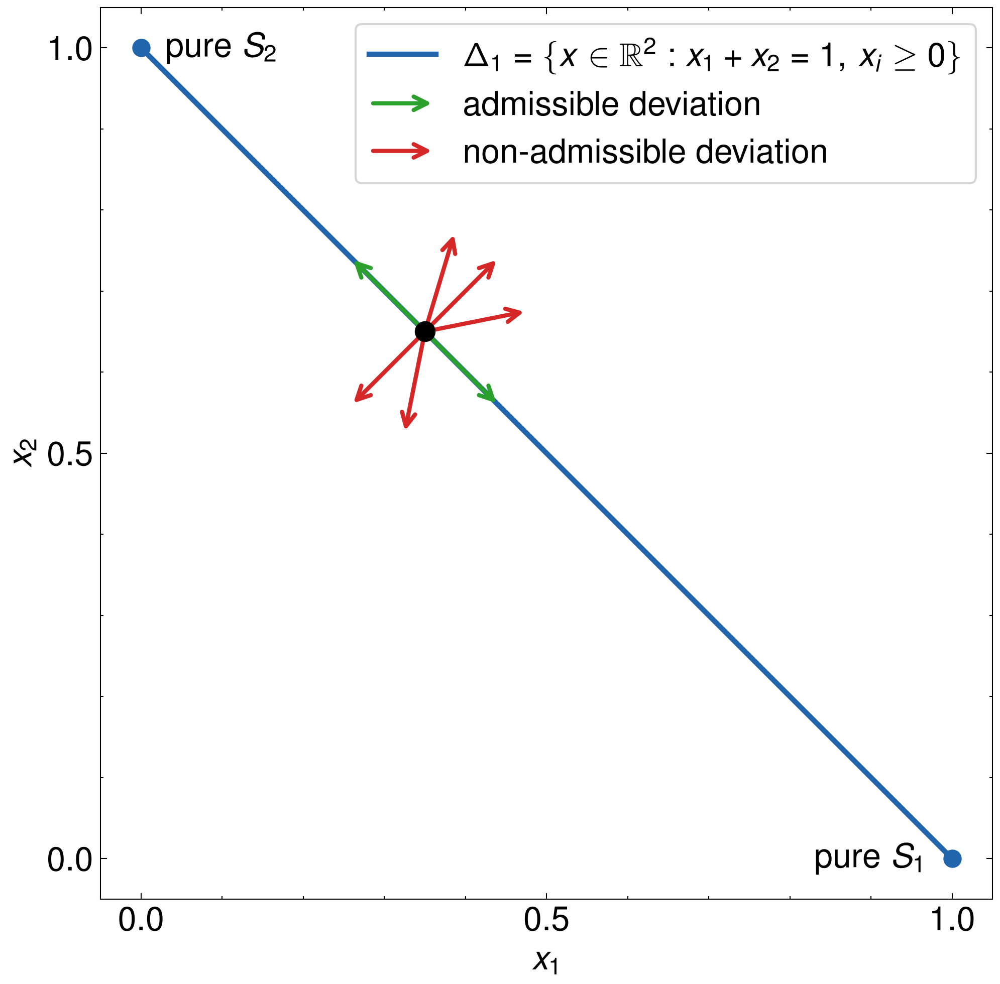

In [15]:

from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from matplotlib.legend_handler import HandlerPatch

class HandlerArrow(HandlerPatch):
    def create_artists(self, legend, orig_handle,
                       xdescent, ydescent, width, height, fontsize, trans):
        p = FancyArrowPatch(
            posA=(xdescent, height / 2 - ydescent),
            posB=(width - xdescent, height / 2 - ydescent),
            arrowstyle='->', mutation_scale=fontsize,
            color=orig_handle.get_edgecolor(),
            linewidth=orig_handle.get_linewidth(),
            transform=trans,
        )
        return [p]

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot([0, 1], [1, 0], color='#2166ac', linewidth=2.5)

ax.scatter([1, 0], [0, 1], s=60, color='#2166ac', zorder=4)

ax.annotate(r'pure $S_1$', xy=(1, 0), xytext=(0.83, 0), va='center', ha='left')
ax.annotate(r'pure $S_2$', xy=(0, 1), xytext=(0.03, 1), va='center', ha='left')

# Equilibrium
x_eq, y_eq = 0.35, 0.65
ax.scatter([x_eq], [y_eq], s=80, color='black', zorder=5)

L = 0.13
d = L / 2**0.5

adm_color = '#2ca02c'
for sign in [1, -1]:
    ax.annotate("", xy=(x_eq + sign*d, y_eq - sign*d), xytext=(x_eq, y_eq),
                arrowprops=dict(arrowstyle='->', color=adm_color, lw=2.0))

inadm_color = '#d62728'
def norm(dx, dy):
    n = (dx**2 + dy**2)**0.5
    return dx/n, dy/n

inadm_dirs = [
    norm(1, 1), norm(-1, -1), norm(1, 0.2), norm(-0.2, -1), norm(0.3, 1),
]
for dx, dy in inadm_dirs:
    ax.annotate("", xy=(x_eq + L*dx, y_eq + L*dy), xytext=(x_eq, y_eq),
                arrowprops=dict(arrowstyle='->', color=inadm_color, lw=2.0))

# Legend with proper arrows
simplex_line = Line2D([0], [0], color='#2166ac', linewidth=2.5,
                      label=r'$\Delta_1 = \{x \in \mathbb{R}^2 : x_1 + x_2 = 1,\, x_i \geq 0\}$')
adm_patch = FancyArrowPatch((0, 0), (1, 0), color=adm_color, linewidth=2.0,
                             arrowstyle='->', mutation_scale=15,
                             label='admissible deviation')
inadm_patch = FancyArrowPatch((0, 0), (1, 0), color=inadm_color, linewidth=2.0,
                               arrowstyle='->', mutation_scale=15,
                               label='non-admissible deviation')

ax.legend(handles=[simplex_line, adm_patch, inadm_patch],
          handler_map={FancyArrowPatch: HandlerArrow()},
          loc='upper right', frameon=True)

ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.set_aspect('equal')
ax.set_xticks([0, 0.5, 1])
ax.set_yticks([0, 0.5, 1])
fig.savefig('simplex_figure.pdf', dpi=300, bbox_inches='tight')

fig.tight_layout()
plt.show()

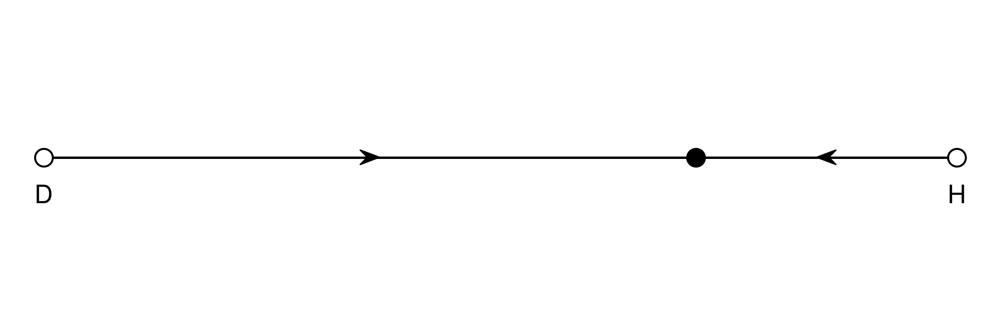

In [16]:
import pynamo_egt as pn

fig, ax = pn.phase_portrait(game=pn.examples.games.hawk_dove)
ax.set_title("");

In [ ]:
FIGSIZE = (8, 8)
FONTSIZE = 18  # change this to scale all text in the four panels

plt.rcParams.update({
    'font.size': FONTSIZE,
    'axes.labelsize': FONTSIZE,
    'xtick.labelsize': FONTSIZE,
    'ytick.labelsize': FONTSIZE,
})

# RPS
fig, ax = pn.phase_portrait(
    game=pn.examples.games.good_rps,
    figsize=FIGSIZE,
    starts=[
        [0.15, 0.15],
        [0.15, 0.70],
        [0.70, 0.15],
    ],
    trajectory_color="black",
    trajectory_linewidth=1.2,
    show_edge_flow=True,
    show_speed=True,
    speed_cmap=plt.cm.plasma_r,
    speed_grid=80,
    speed_levels=200,
    simplex_font_size=FONTSIZE,
    equilibrium_size=80,
)
ax.set_title("")
fig.savefig("_panel_rps.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# Hawk-Dove
fig, ax = pn.phase_portrait(
    game=pn.examples.games.two_population_hawk_dove,
    figsize=FIGSIZE,
    starts=[[0.25, 0.85], [0.35, 0.35], [0.9, 0.9], [0.85, 0.25], [0.85, 0.75], [0.75, 0.85]],
    show_speed=True,
    speed_levels=200,
    show_vector_field=True,
    vector_color="white",
    speed_cmap=plt.cm.cividis,
    trajectory_linewidth=1.5,
)
ax.set_title("")
ax.set_xlabel(ax.get_xlabel(), fontsize=FONTSIZE)
ax.set_ylabel(ax.get_ylabel(), fontsize=FONTSIZE)
fig.savefig("_panel_hawk_dove.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# Four-strategy
fig, ax = pn.phase_portrait(
    game=pn.examples.games.chaotic_four_strategy_game,
    figsize=FIGSIZE,
    view_elev=20,
    view_azim=-56,
    starts=[[0.22, 0.25, 0.25], [0.20, 0.20, 0.60], [0.45, 0.10, 0.20]],
    tmax=90,
    trajectory_step=0.02,
    trajectory_color="royalblue",
    trajectory_linewidth=1.2,
    trajectory_arrows=[0.001],
    show_speed=False,
    show_vector_field=False,
    show_faces=True,
    face_colors=["#666666", "#999999", "#CCCCCC", "none"],
    face_alpha=0.18,
    simplex_font_size=FONTSIZE,
    equilibrium_size=30,
    equilibrium_edgecolor="black",
)
ax.set_title("")
ax.set_box_aspect((1, 1, 1), zoom=1.2)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.03, top=0.98)
fig.savefig("_panel_four_strategy.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# Cyclic mismatching pennies
fig, ax = pn.phase_portrait(
    game=pn.examples.games.cyclic_mismatching_pennies,
    figsize=FIGSIZE,
    view_elev=16,
    view_azim=127,
    show_faces=True,
    face_alpha=0.5,
    starts=[[0.52, 0.50, 0.48], [0.60, 0.50, 0.40], [0.70, 0.45, 0.35], [0.20, 0.65, 0.75]],
    tmax=400,
    trajectory_arrows=[],
    trajectory_color=["royalblue", "firebrick", "goldenrod", "darkgreen"],
    trajectory_linewidth=1.5,
    equilibrium_size=25,
    simplex_font_size=FONTSIZE,
)
ax.set_title("")
ax.set_box_aspect((1, 1, 1), zoom=1.1)
fig.subplots_adjust(left=0.03, right=0.97, bottom=0.03, top=0.90)
fig.savefig("_panel_cube.png", dpi=200, bbox_inches="tight")
plt.close(fig)

print("panels saved")

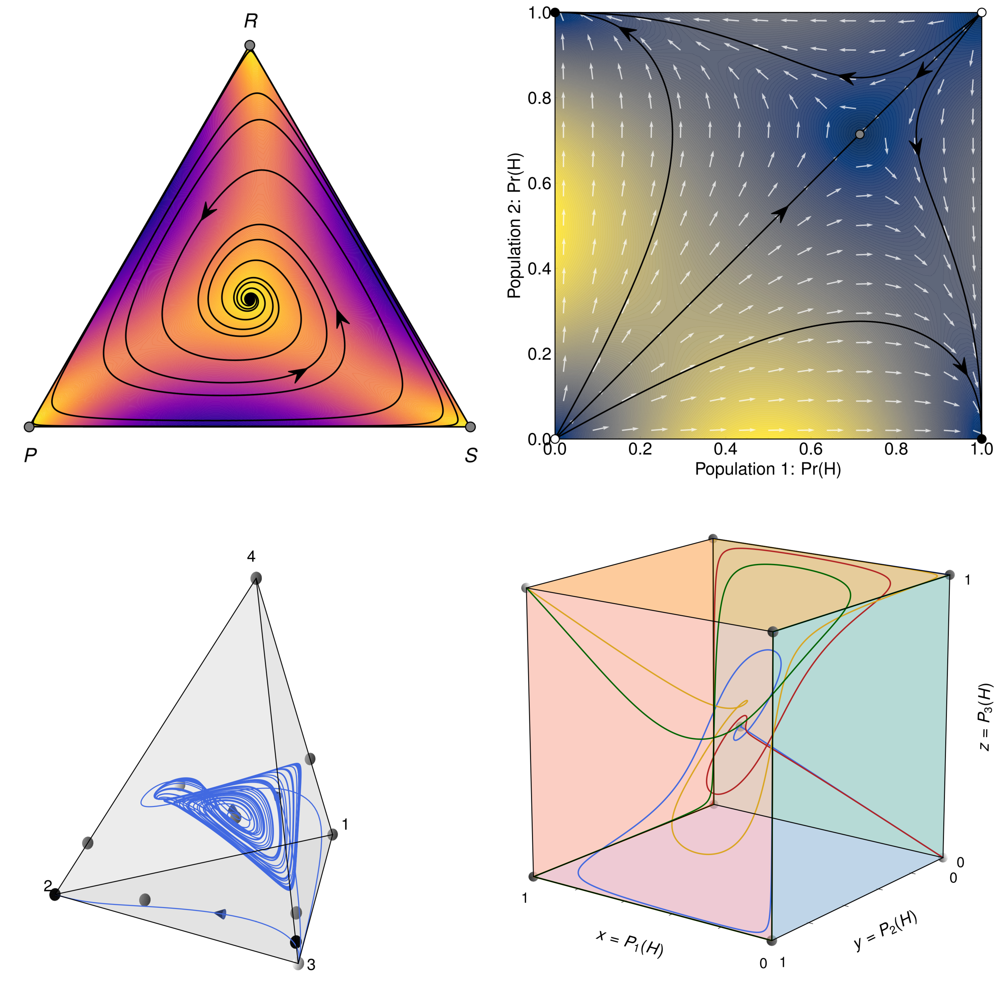

In [18]:
import matplotlib.image as mpimg

panels = [
    mpimg.imread("_panel_rps.png"),
    mpimg.imread("_panel_hawk_dove.png"),
    mpimg.imread("_panel_four_strategy.png"),
    mpimg.imread("_panel_cube.png"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, img in zip(axes.flat, panels):
    ax.imshow(img)
    ax.axis("off")

fig.tight_layout(pad=0.5)
fig.savefig("gallery.pdf", bbox_inches="tight", dpi=200)
plt.show()

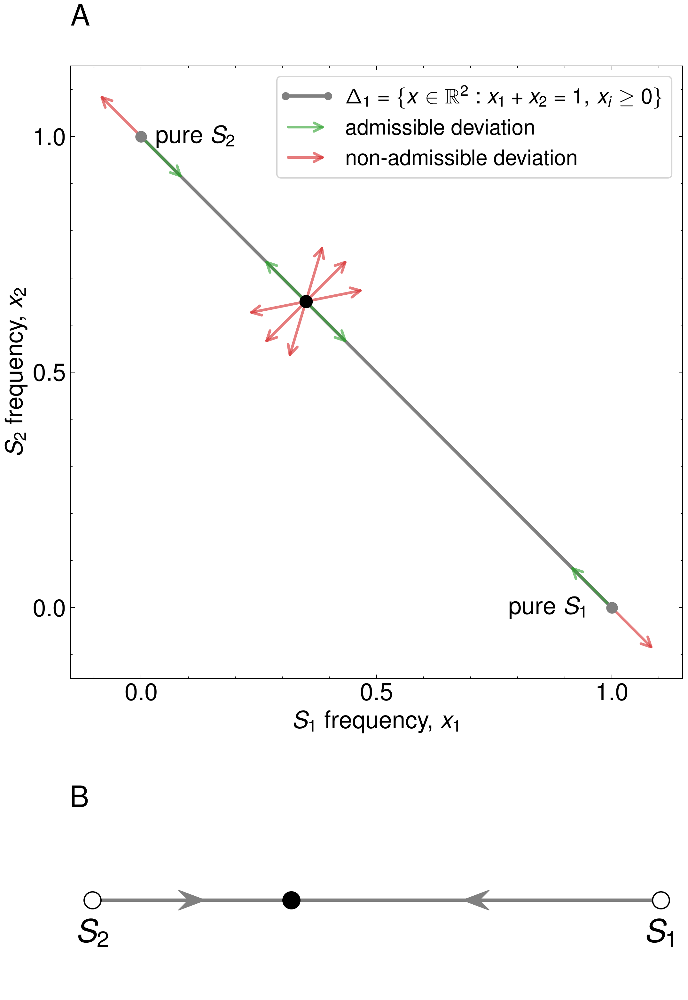

In [19]:
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from matplotlib.legend_handler import HandlerBase, HandlerPatch

class HandlerSimplexLine(HandlerBase):
    def create_artists(self, legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans):
        y = height / 2 - ydescent
        x0, x1 = xdescent, width - xdescent
        line = Line2D([x0, x1], [y, y],
                      color=orig_handle.get_color(),
                      linewidth=orig_handle.get_linewidth(),
                      transform=trans)
        dots = Line2D([x0, x1], [y, y],
                      color=orig_handle.get_color(),
                      linewidth=0,
                      marker='o',
                      markersize=orig_handle.get_markersize(),
                      markerfacecolor=orig_handle.get_markerfacecolor(),
                      markeredgewidth=orig_handle.get_markeredgewidth(),
                      transform=trans)
        return [line, dots]

class HandlerArrow(HandlerPatch):
    def create_artists(self, legend, orig_handle,
                       xdescent, ydescent, width, height, fontsize, trans):
        p = FancyArrowPatch(
            posA=(xdescent, height / 2 - ydescent),
            posB=(width - xdescent, height / 2 - ydescent),
            arrowstyle='->', mutation_scale=fontsize,
            color=orig_handle.get_edgecolor(),
            linewidth=orig_handle.get_linewidth(),
            alpha=orig_handle.get_alpha(),
            transform=trans,
        )
        return [p]

SIMPLEX_COLOR = 'gray'
SIMPLEX_LW = 2.5
ARROW_ALPHA = 0.6

fig = plt.figure(figsize=(8, 11))

# ── Panel A ──────────────────────────────────────────────────────────────────
ax_a = fig.add_axes([0.10, 0.36, 0.80, 0.58])

ax_a.plot([0, 1], [1, 0], color=SIMPLEX_COLOR, linewidth=SIMPLEX_LW)
ax_a.scatter([1, 0], [0, 1], s=60, color=SIMPLEX_COLOR, zorder=4)
ax_a.annotate(r'pure $S_1$', xy=(1, 0), xytext=(0.78, 0), va='center', ha='left')
ax_a.annotate(r'pure $S_2$', xy=(0, 1), xytext=(0.03, 1), va='center', ha='left')

x_eq, y_eq = 0.35, 0.65
ax_a.scatter([x_eq], [y_eq], s=80, color='black', zorder=5)

L = 0.13
d = L / 2**0.5
adm_color = '#2ca02c'
inadm_color = '#d62728'

def norm(dx, dy):
    n = (dx**2 + dy**2)**0.5
    return dx/n, dy/n

# Interior rest point — admissible (both directions along simplex)
for sign in [1, -1]:
    ax_a.annotate("", xy=(x_eq + sign*d, y_eq - sign*d), xytext=(x_eq, y_eq),
                  arrowprops=dict(arrowstyle='->', color=adm_color, lw=2.0, alpha=ARROW_ALPHA))

# Interior rest point — non-admissible (3 symmetric pairs)
for dx, dy in [norm(1,1), norm(-1,-1), norm(1,0.2), norm(-1,-0.2), norm(0.3,1), norm(-0.3,-1)]:
    ax_a.annotate("", xy=(x_eq + L*dx, y_eq + L*dy), xytext=(x_eq, y_eq),
                  arrowprops=dict(arrowstyle='->', color=inadm_color, lw=2.0, alpha=ARROW_ALPHA))

# Boundary point (1, 0) — admissible: inward along simplex; non-admissible: outward along simplex
ax_a.annotate("", xy=(1 + L*norm(-1,1)[0], 0 + L*norm(-1,1)[1]), xytext=(1, 0),
              arrowprops=dict(arrowstyle='->', color=adm_color, lw=2.0, alpha=ARROW_ALPHA))
ax_a.annotate("", xy=(1 + L*norm(1,-1)[0], 0 + L*norm(1,-1)[1]), xytext=(1, 0),
              arrowprops=dict(arrowstyle='->', color=inadm_color, lw=2.0, alpha=ARROW_ALPHA))

# Boundary point (0, 1) — admissible: inward along simplex; non-admissible: outward along simplex
ax_a.annotate("", xy=(0 + L*norm(1,-1)[0], 1 + L*norm(1,-1)[1]), xytext=(0, 1),
              arrowprops=dict(arrowstyle='->', color=adm_color, lw=2.0, alpha=ARROW_ALPHA))
ax_a.annotate("", xy=(0 + L*norm(-1,1)[0], 1 + L*norm(-1,1)[1]), xytext=(0, 1),
              arrowprops=dict(arrowstyle='->', color=inadm_color, lw=2.0, alpha=ARROW_ALPHA))

simplex_handle = Line2D([0, 1], [0, 0], color=SIMPLEX_COLOR, linewidth=SIMPLEX_LW,
                        marker='o', markersize=6, markerfacecolor=SIMPLEX_COLOR, markeredgewidth=0,
                        label=r'$\Delta_1 = \{x \in \mathbb{R}^2 : x_1 + x_2 = 1,\, x_i \geq 0\}$')
adm_handle = FancyArrowPatch((0,0),(1,0), color=adm_color, linewidth=2.0,
                             arrowstyle='->', mutation_scale=15, alpha=ARROW_ALPHA,
                             label='admissible deviation')
inadm_handle = FancyArrowPatch((0,0),(1,0), color=inadm_color, linewidth=2.0,
                               arrowstyle='->', mutation_scale=15, alpha=ARROW_ALPHA,
                               label='non-admissible deviation')

ax_a.legend(handles=[simplex_handle, adm_handle, inadm_handle],
            handler_map={Line2D: HandlerSimplexLine(), FancyArrowPatch: HandlerArrow()},
            loc='upper right', frameon=True)
ax_a.set_xlim(-0.15, 1.15)
ax_a.set_ylim(-0.15, 1.15)
ax_a.set_xlabel('$S_1$ frequency, $x_1$')
ax_a.set_ylabel('$S_2$ frequency, $x_2$')
ax_a.set_aspect('equal')
ax_a.set_xticks([0, 0.5, 1])
ax_a.set_yticks([0, 0.5, 1])
ax_a.text(0, 1.1, 'A', transform=ax_a.transAxes, fontsize=22, fontweight='bold', va='top')

# ── Panel B ──────────────────────────────────────────────────────────────────
ax_b = fig.add_axes([0.10, 0.06, 0.80, 0.18])

game_1d = pn.Game(
    name="",
    payoffs=np.array([[0, 7], [13, 0]], dtype=float),
    strategy_labels=[r"$S_1$", r"$S_2$"],
)
pn.phase_portrait(
    game_1d, fig=fig, ax=ax_b,
    trajectory_color=SIMPLEX_COLOR,
    trajectory_linewidth=SIMPLEX_LW,
    sink_color='black',
    source_color='white',
    equilibrium_edgecolor='black',
    equilibrium_size=160,
    simplex_font_size=24,
    arrow_size=0.08,
    arrow_width=0.03,
)
ax_b.set_title("")
ax_b.text(0, 1.1, 'B', transform=ax_b.transAxes, fontsize=22, fontweight='bold', va='top')

fig.savefig('simplex_figure_AB.pdf', dpi=300, bbox_inches='tight')
plt.show()